# 01 - Time-series factor regressions (CAPM, FF3, Carhart, FF5) and GRS

Every number below is produced by `factors.pipeline.stage_timeseries`. The first part uses **SYNTHETIC** data (known truth: the 25 portfolios follow FF5 with zero alpha; `ACTIVE_FUND` has a true alpha of 0.15%/month). The second part uses **REAL** Kenneth French data and US style ETFs if they have been downloaded (`scripts/download_french_data.py`, `scripts/download_market_data.py`).

In [1]:
import logging

import pandas as pd
from IPython.display import Image, display

from factors import pipeline as pl
from factors.data import DataUnavailableError  # noqa: F401 - used by the real-data cells

logging.basicConfig(level=logging.WARNING)
pd.set_option("display.width", 160, "display.max_columns", 20)

def show(ctx, nn, name):
    display(Image(filename=str(ctx.fig(nn, name))))

## SYNTHETIC

In [2]:
syn = pl.Context('synthetic', 'fast')
pl.ensure_synthetic(syn)
res = pl.stage_timeseries(syn)
c = res['coef']
c[(c.term == 'alpha')].pivot(index='asset', columns='model', values='t_hac').round(2)

model,CAPM,Carhart4,FF3,FF5,FF5_plus_MOM
asset,,,,,
ACTIVE_FUND,5.08,4.22,3.90,3.81,4.04
MARKET_FUND,0.74,0.72,0.85,0.79,0.69
MOMENTUM_FUND,2.75,0.54,3.39,3.33,0.41
QUALITY_FUND,3.22,2.23,2.42,-0.04,-0.14
SMALL_FUND,2.03,1.47,1.37,1.74,1.89
VALUE_FUND,2.27,-0.26,-0.20,-0.09,-0.14


In [3]:
res['grs'][['model', 'statistic', 'pvalue', 'df1', 'df2', 'T']]

,model,statistic,pvalue,df1,df2,T
0,CAPM,1.545048,0.048490,25,334,360
1,FF3,1.220158,0.217629,25,332,360
2,Carhart4,1.092923,0.348239,25,331,360
3,FF5,0.886420,0.624947,25,330,360


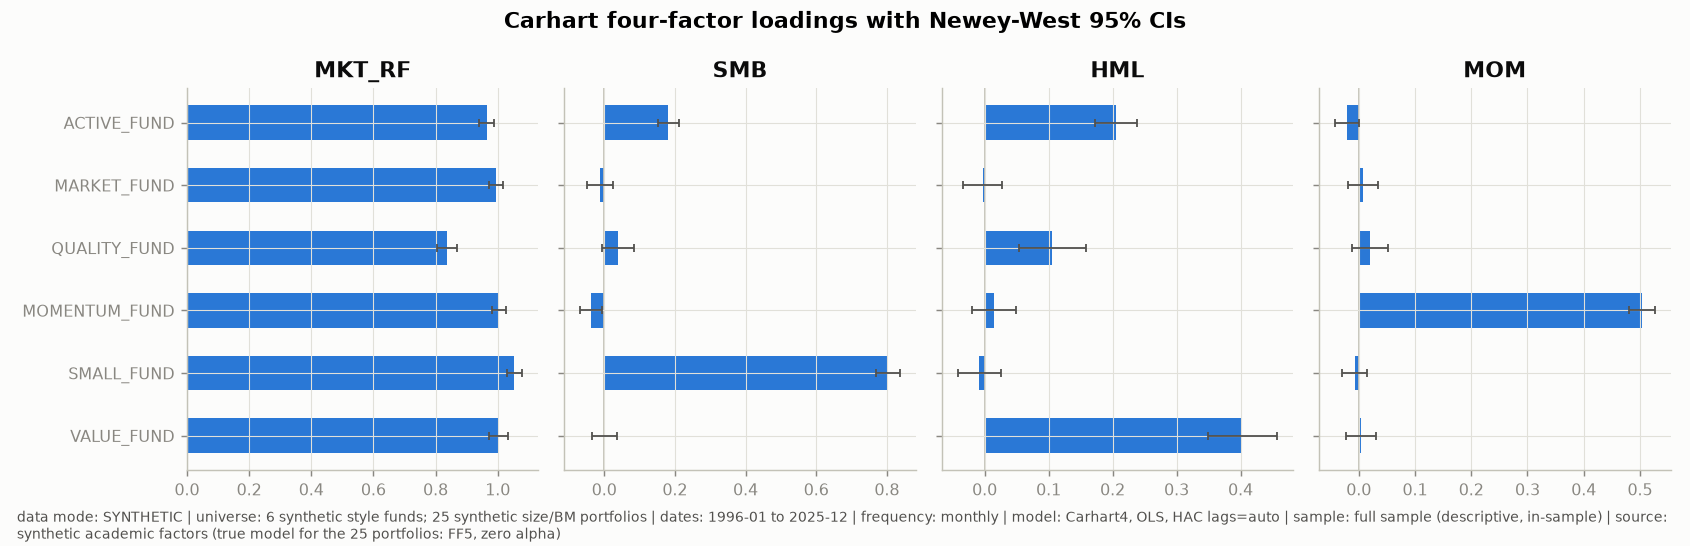

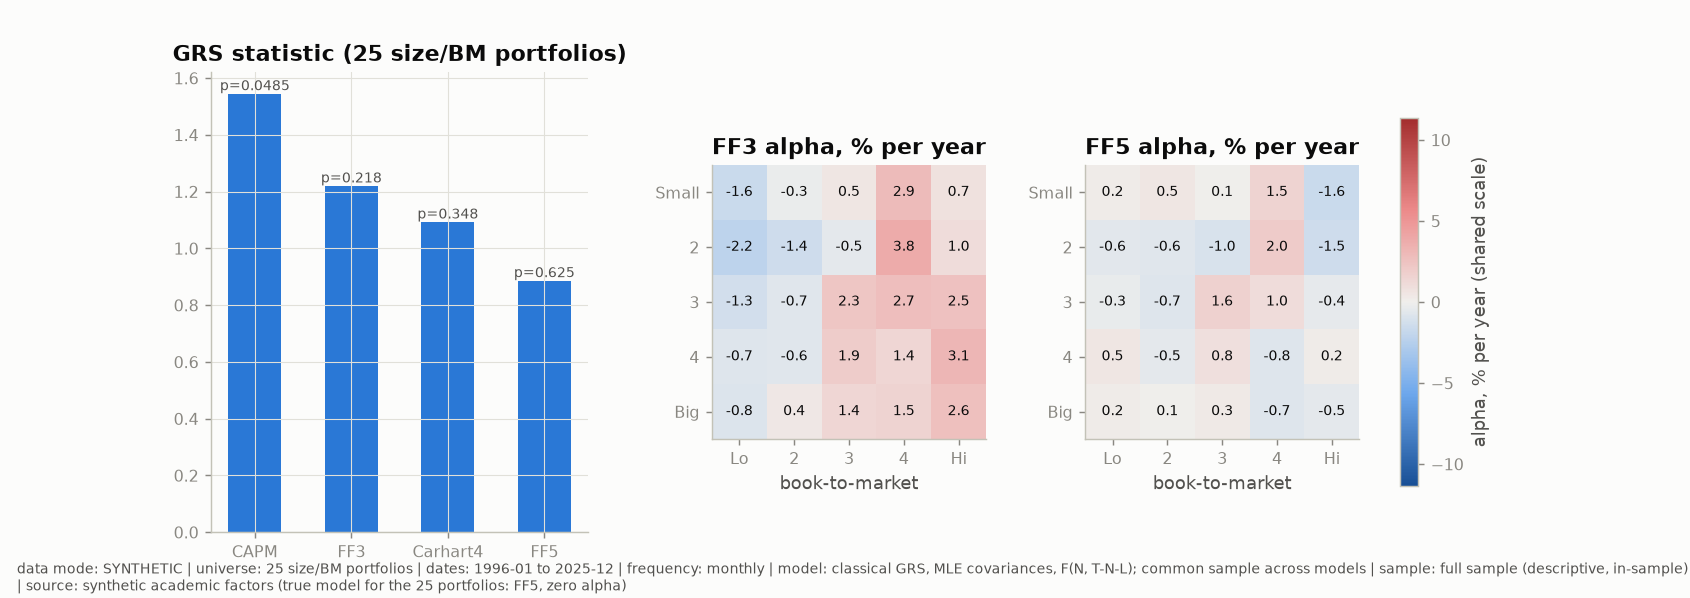

In [4]:
show(syn, '01', 'factor_loadings_hac')
show(syn, '04', 'grs_and_25_portfolio_alphas')

## REAL (French factors, US style ETFs)

,model,statistic,pvalue,df1,df2,T,sample_start,sample_end
0,CAPM,4.167417,9.523011e-11,25,733,759,1963-07,2026-09
1,FF3,3.627834,9.374586e-09,25,731,759,1963-07,2026-09
2,Carhart4,3.201178,3.201787e-07,25,730,759,1963-07,2026-09
3,FF5,3.213685,2.895508e-07,25,729,759,1963-07,2026-09


term,HML,MKT_RF,MOM,SMB,alpha
asset,,,,,
IWD,0.382,0.913,-0.026,-0.081,-0.001
IWN,0.591,0.950,0.030,0.799,-0.001
MTUM,-0.023,1.088,0.501,-0.037,-0.001
QUAL,-0.016,0.976,-0.004,-0.152,-0.000
SPY,0.018,0.978,-0.024,-0.161,0.000
USMV,0.064,0.705,0.050,-0.222,-0.000


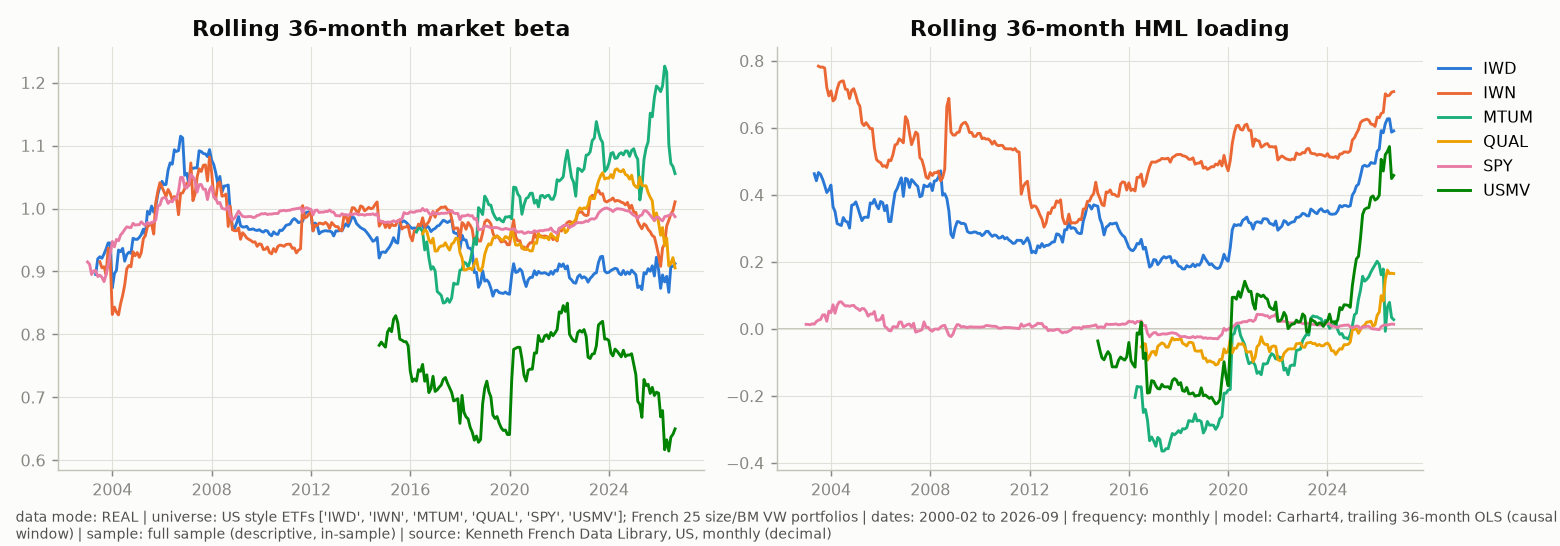

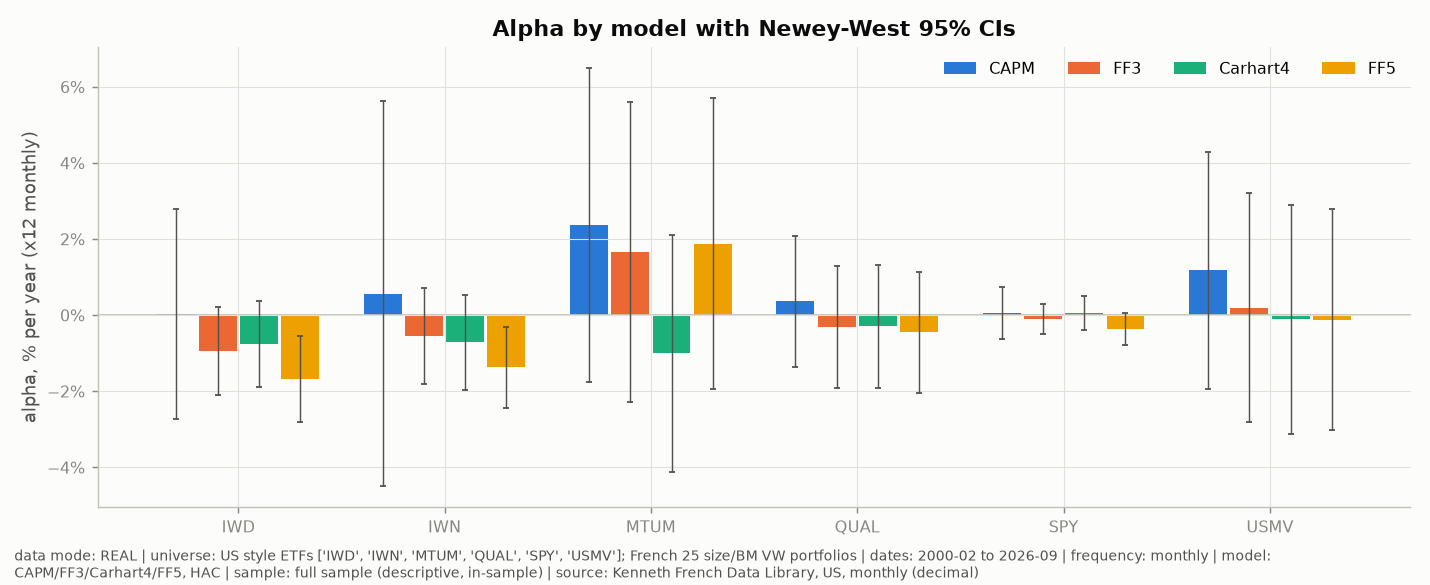

In [5]:
try:
    real = pl.Context('real')
    rr = pl.stage_timeseries(real)
    display(rr['grs'][['model', 'statistic', 'pvalue', 'df1', 'df2', 'T', 'sample_start', 'sample_end']])
    c = rr['coef']
    display(c[c.model == 'Carhart4'].pivot(index='asset', columns='term', values='coef').round(3))
    show(real, '02', 'rolling_betas')
    show(real, '03', 'alpha_comparison')
except DataUnavailableError as e:
    print('REAL data not cached - skipped:', e)

**Reading the output.** Alpha is the average return not explained by the factors *in this sample*; its HAC confidence interval is wide for short ETF histories. GRS is the classical finite-sample test (i.i.d. normal residuals) and is reported separately from HAC inference.